In [1]:
%pip install gymnasium
%pip install torch
%pip install joblib

import gymnasium as gym

import matplotlib.pyplot as plt
import numpy as np
import torch

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# use GPU if available, or MPS, otherwise, use CPU
device=None
#if torch.cuda.is_available():
#    device = torch.device('cuda')
#elif torch.backends.mps.is_available():
#    device = torch.device('mps')
#else:
#    device = torch.device('cpu')
device = torch.device('cpu')
    
print('device:',device)

device: cpu


In [5]:
# Frozen lake: Gymnasium's built-in FrozenLake-v1, created with gym.make.
# Map letters: S = start, F = frozen, H = hole, G = goal.
# Actions: 0 = left, 1 = down, 2 = right, 3 = up.
# Reward 1 on reaching the goal; the episode terminates on reaching the goal or a hole,
# and is truncated after max_steps.

def FrozenLake(lake, slip, max_steps, seed=None):
    """Build FrozenLake-v1. With probability 1 - slip the agent moves the intended way;
    otherwise it slips to one of the two perpendicular directions (slip/2 each)."""
    env = gym.make('FrozenLake-v1', desc=lake, is_slippery=slip > 0, success_rate=1.0 - slip,
                   max_episode_steps=max_steps)
    env.reset(seed=seed)  # seeds the environment's RNG once; later resets continue from it
    return env


class FrozenLakeImageWrapper:
    """Encodes each FrozenLake state as a 4-channel image: agent position, start, holes, goal."""
    def __init__(self, env):
        self.env = env

        lake = np.array([list(row) for row in env.unwrapped.desc.astype(str)])
        self.lake_flat = lake.reshape(-1)
        self.n_states = env.observation_space.n
        self.n_actions = env.action_space.n
        self.h = lake.shape[0]
        self.w = lake.shape[1]
        self.state_shape = (4, lake.shape[0], lake.shape[1])

        lake_image = [(lake == c).astype(float) for c in ['S', 'H', 'G']]

        self.state_image = {}
        for state in range(self.n_states):
            state_layer = np.zeros(lake.shape)
            state_layer[np.unravel_index(state, lake.shape)] = 1
            self.state_image[state] = np.stack([state_layer] + lake_image)

    def encode_state(self, state):
        return self.state_image[state]

    def decode_policy(self, dqn):
        states = np.array([self.encode_state(s) for s in range(self.n_states)])
        q = dqn(states).detach().cpu().numpy()
        return q.argmax(axis=1), q.max(axis=1)

    def reset(self):
        state, info = self.env.reset()
        return state, self.encode_state(state)

    def step(self, action):
        next_state, reward, terminated, truncated, info = self.env.step(action)
        return next_state, self.encode_state(next_state), reward, terminated, truncated, info

    def render(self):
        return self.env.render()


# Big lake
big_lake = ['SFFFFFFF',
            'FFFFFFFF',
            'FFFHFFFF',
            'FFFFFHFF',
            'FFFHFFFF',
            'FHHFFFHF',
            'FHFFHFHF',
            'FFFHFFFG']

# Small lake
small_lake = ['SFFF',
              'FHFH',
              'FFFH',
              'HFFG']


seed = 0
gamma=0.9

def value_iteration(env, gamma, theta, max_iterations):
    """Value iteration on the environment's transition table env.unwrapped.P,
    where P[s][a] is a list of (probability, next_state, reward, terminated)."""
    P = env.unwrapped.P
    n_states, n_actions = env.observation_space.n, env.action_space.n
    value = np.zeros(n_states)

    def q_values(state):
        return np.array([sum(p * (r + (0.0 if done else gamma * value[ns])) for p, ns, r, done in P[state][a])
                         for a in range(n_actions)])

    for _ in range(max_iterations):
        delta = 0
        for state in range(n_states):
            best_value = q_values(state).max()
            delta = max(delta, abs(best_value - value[state]))
            value[state] = best_value
        if delta < theta:
            print("Converged")
            break

    policy = np.array([q_values(state).argmax() for state in range(n_states)])
    return policy, value


env1 = FrozenLake(small_lake, slip=0.0, max_steps=16, seed=seed)
d_optimal_policy4x4, d_optimal_vals4x4 = value_iteration(env1, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Deterministic Value iteration 4x4')
print("Optimal Policy:", d_optimal_policy4x4)
print("Optimal Values:", d_optimal_vals4x4)
print('')


env2 = FrozenLake(big_lake, slip=0.0, max_steps=64, seed=seed)
d_optimal_policy8x8, d_optimal_vals8x8 = value_iteration(env2, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Deterministic Value iteration 8x8')
print("Optimal Policy:", d_optimal_policy8x8)
print("Optimal Values:", d_optimal_vals8x8)
print('')

env5 = FrozenLake(small_lake, slip=0.4, max_steps=16, seed=seed)
s_40_optimal_policy4x4, s_40_optimal_vals4x4 = value_iteration(env5, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Stochastic 40% Value iteration 4x4')
print("Optimal Policy:", s_40_optimal_policy4x4)
print("Optimal Values:", s_40_optimal_vals4x4)
print('')


env6 = FrozenLake(big_lake, slip=0.4, max_steps=64, seed=seed)
s_40_optimal_policy8x8, s_40_optimal_vals8x8 = value_iteration(env6, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Stochastic 40% Value iteration 8x8')
print("Optimal Policy:", s_40_optimal_policy8x8)
print("Optimal Values:", s_40_optimal_vals8x8)
print('')

env9 = FrozenLake(small_lake, slip=0.8, max_steps=16, seed=seed)
s_80_optimal_policy4x4, s_80_optimal_vals4x4 = value_iteration(env9, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Stochastic 80% Value iteration 4x4')
print("Optimal Policy:", s_80_optimal_policy4x4)
print("Optimal Values:", s_80_optimal_vals4x4)
print('')

env10 = FrozenLake(big_lake, slip=0.8, max_steps=64, seed=seed)
s_80_optimal_policy8x8, s_80_optimal_vals8x8 = value_iteration(env10, gamma, theta=1e-8, max_iterations=1024)
# Display the optimal policy and state values
print('## Stochastic 80% Value iteration 8x8')
print("Optimal Policy:", s_80_optimal_policy8x8)
print("Optimal Values:", s_80_optimal_vals8x8)
print('# Done')

class ReplayBuffer:
    """Circular replay buffer stored in preallocated numpy arrays.

    draw() returns a tuple of batched arrays (states, actions, rewards,
    next_states, terminateds, truncateds), so train_step no longer has to
    rebuild arrays from a list of Python tuples on every step. Sampling is
    the same as the old deque version: index i counts from the oldest stored
    transition, drawn with replacement from the global numpy RNG.
    """
    def __init__(self, buffer_size, random_state):
        self.buffer_size = buffer_size
        self.random_state = random_state
        self.size = 0   # number of transitions stored
        self.pos = 0    # next slot to write; once full, also the oldest transition
        self.states = None  # allocated on the first append, once the state shape is known

    def __len__(self):
        return self.size

    def append(self, transition):
        state, action, reward, next_state, terminated, truncated = transition
        if self.states is None:
            shape = (self.buffer_size,) + np.shape(state)
            self.states = np.empty(shape, dtype=np.float32)
            self.next_states = np.empty(shape, dtype=np.float32)
            self.actions = np.empty(self.buffer_size, dtype=np.int64)
            self.rewards = np.empty(self.buffer_size, dtype=np.float32)
            self.terminateds = np.empty(self.buffer_size, dtype=np.float32)
            self.truncateds = np.empty(self.buffer_size, dtype=np.float32)
        i = self.pos
        self.states[i] = state
        self.actions[i] = action
        self.rewards[i] = reward
        self.next_states[i] = next_state
        self.terminateds[i] = terminated
        self.truncateds[i] = truncated
        self.pos = (self.pos + 1) % self.buffer_size
        self.size = min(self.size + 1, self.buffer_size)

    def draw(self, batch_size):
        # Ensure the batch size does not exceed the buffer size
        batch_size = min(batch_size, self.size)
        # Random sample (with replacement), indexed oldest-first like the old deque
        indices = np.random.choice(self.size, size=batch_size)
        if self.size == self.buffer_size:
            indices = (indices + self.pos) % self.buffer_size
        return (self.states[indices], self.actions[indices], self.rewards[indices],
                self.next_states[indices], self.terminateds[indices], self.truncateds[indices])

def plot_results(max_episodes, model_name, env_name, rewards, best_reward, n_boot=1000, seed=0):
    """Plots smoothed discounted reward as a fraction of the best achievable reward,
    so results on different lakes and slip levels share one scale (1.0 = optimal).
    best_reward is the optimal value of the start state from value iteration.

    The line is the mean across runs; the band is a 95% percentile bootstrap confidence
    interval of that mean (n_boot resamples of the runs, the same statistic as seaborn's
    errorbar="ci"), computed for every episode at once with numpy. The fixed seed makes
    the band identical each time the cell is re-run."""
    fractions = np.asarray(rewards) / best_reward                 # [runs, episodes]
    n_runs, n_points = fractions.shape
    episodes = np.arange(max_episodes - n_points, max_episodes)   # smoothing window drops the first episodes

    resample = np.random.default_rng(seed).integers(0, n_runs, size=(n_boot, n_runs))
    boot_means = fractions[resample].mean(axis=1)                 # [n_boot, episodes]
    low, high = np.percentile(boot_means, [2.5, 97.5], axis=0)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(episodes, fractions.mean(axis=0))
    ax.fill_between(episodes, low, high, alpha=0.2, linewidth=0)
    ax.axhline(1.0, color='grey', linestyle='--', linewidth=1)
    ax.set_ylim(bottom=-0.05)
    ax.set_xlabel('Episode')
    ax.set_ylabel('Fraction of optimal reward')
    ax.set_title("Discounted reward / optimal ({:.3f}) {} {}".format(best_reward, model_name, env_name))

    plt.show()

max_episodes = 4000
gamma = 0.9
sample_runs = 32

Converged
## Deterministic Value iteration 4x4
Optimal Policy: [1 2 1 0 1 0 1 0 2 1 1 0 0 2 2 0]
Optimal Values: [0.59049 0.6561  0.729   0.6561  0.6561  0.      0.81    0.      0.729
 0.81    0.9     0.      0.      0.9     1.      0.     ]

Converged
## Deterministic Value iteration 8x8
Optimal Policy: [1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 0 1 2 1 1 2 2 2 2 1 0 1 1 2 2 3 0 1
 1 2 1 1 0 0 2 2 1 0 1 1 0 2 3 0 1 0 1 2 2 3 0 2 2 2 0]
Optimal Values: [0.25418658 0.28242954 0.3138106  0.34867844 0.38742049 0.43046721
 0.4782969  0.531441   0.28242954 0.3138106  0.34867844 0.38742049
 0.43046721 0.4782969  0.531441   0.59049    0.3138106  0.34867844
 0.38742049 0.         0.4782969  0.531441   0.59049    0.6561
 0.34867844 0.38742049 0.43046721 0.4782969  0.531441   0.
 0.6561     0.729      0.3138106  0.34867844 0.38742049 0.
 0.59049    0.6561     0.729      0.81       0.28242954 0.
 0.         0.59049    0.6561     0.729      0.         0.9
 0.3138106  0.         0.4782969  0.531441   0

In [7]:
class DeepQNetwork(torch.nn.Module):
    def __init__(self, env, learning_rate, kernel_size, conv_out_channels,
                 fc_out_features, seed):
        torch.nn.Module.__init__(self)
        torch.manual_seed(seed)
        self.random_state = np.random.RandomState(seed)
        self.n_actions = env.n_actions

        self.conv_layer = torch.nn.Conv2d(in_channels=env.state_shape[0], out_channels=conv_out_channels,
                                          kernel_size=kernel_size, stride=1)

        # Get the height and width
        h = env.h
        w = env.w

        h = h - kernel_size + 1
        w = w - kernel_size + 1

        self.fc_layer = torch.nn.Linear(in_features=h * w * conv_out_channels, out_features=fc_out_features)
        self.output_layer = torch.nn.Linear(in_features=fc_out_features, out_features=self.n_actions)

        self.optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate, foreach=True)

    def forward(self, x):
        x = torch.as_tensor(x, dtype=torch.float32, device=device)
        x = torch.relu(self.conv_layer(x)).flatten(1)
        x = torch.relu(self.fc_layer(x))
        return self.output_layer(x)

    def train_step(self, transitions, gamma, tdqn):
        # Batched arrays from ReplayBuffer.draw, already float32 / int64, so
        # torch.from_numpy wraps them without copying or converting.
        states, actions, rewards, next_states, terminateds, truncateds = transitions

        actions = torch.from_numpy(actions).to(device)
        rewards = torch.from_numpy(rewards).to(device)
        not_done = torch.from_numpy((1 - terminateds) * (1 - truncateds)).to(device)

        q = self(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            next_q = tdqn(next_states).max(dim=1)[0] * not_done

        target = rewards + gamma * next_q
        loss = torch.nn.functional.mse_loss(q, target)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    def eval_greedy(self, agent_net):
        best = np.flatnonzero(np.isclose(agent_net, agent_net.max()))
        return self.random_state.choice(best)

def deep_q_network_learning(env, max_episodes, learning_rate, gamma, epsilon,
                            batch_size, target_update_frequency, buffer_size,
                            kernel_size, conv_out_channels, fc_out_features, seed):
    random_state = np.random.RandomState(seed)
    replay_buffer = ReplayBuffer(buffer_size, random_state)

    dqn = DeepQNetwork(env, learning_rate, kernel_size, conv_out_channels,
                       fc_out_features, seed=seed)
    dqn.to(device)
    tdqn = DeepQNetwork(env, learning_rate, kernel_size, conv_out_channels,
                        fc_out_features, seed=seed)
    tdqn.to(device)

    epsilon = np.linspace(epsilon, 0, max_episodes)
    # epsilon-greedy exploration strategy

    sums_of_rewards = []

    for i in range(max_episodes):
        state, encoded_state = env.reset()
        sum_of_discounted_rewards=0.0
        terminated = False
        truncated = False
        t = 0

        while (not terminated) and (not truncated):

          action = None
          if random_state.rand() < epsilon[i]:
              action = random_state.choice(env.n_actions)
          else:
              with torch.inference_mode():
                  q = dqn(np.asarray(encoded_state)[None])[0].cpu().numpy()
              action = dqn.eval_greedy(q)

          next_state, encoded_next_state, reward, terminated, truncated, info = env.step(action)

          sum_of_discounted_rewards += gamma**t * reward
          replay_buffer.append((encoded_state, action, reward, encoded_next_state, terminated, truncated))
          state = next_state
          encoded_state = encoded_next_state
          t += 1

          if len(replay_buffer) >= batch_size:
              transitions = replay_buffer.draw(batch_size)
              dqn.train_step(transitions, gamma, tdqn)


        sums_of_rewards.append(sum_of_discounted_rewards)

        if (i % target_update_frequency) == 0:
            tdqn.load_state_dict(dqn.state_dict())

    return torch.tensor(sums_of_rewards)

In [8]:
# Run the independent sample runs in parallel, one process per run.
# joblib's default (loky) backend uses cloudpickle, so classes and functions
# defined in this notebook can be sent to the worker processes.
import os
from joblib import Parallel, delayed

n_jobs = min(sample_runs, os.cpu_count())

def _single_run(learn_fn, lake, slip, max_steps, env_seed, net_seed, kwargs):
    torch.set_num_threads(1)   # tiny networks: one thread per process is fastest
    np.random.seed(net_seed)   # ReplayBuffer.draw uses the global numpy RNG
    env = FrozenLakeImageWrapper(FrozenLake(lake, slip=slip, max_steps=max_steps, seed=env_seed))
    rewards = learn_fn(env, seed=net_seed, **kwargs)
    return rewards.numpy()

def run_samples(learn_fn, lake, slip, max_steps, net_seed=4, window=500, **kwargs):
    """Runs sample_runs independent trainings in parallel; run i uses env seed
    seed+i and network seed net_seed+i. Returns a list of smoothed reward curves.

    Unless buffer_size is passed explicitly, the replay buffer is made big enough to
    keep every transition of the run (max_episodes * max_steps), so rare goal-reaching
    transitions are never evicted. Memory is only used as transitions arrive."""
    kwargs.setdefault('buffer_size', kwargs['max_episodes'] * max_steps)
    results = Parallel(n_jobs=n_jobs, verbose=10)(
        delayed(_single_run)(learn_fn, lake, slip, max_steps, seed + i, net_seed + i, kwargs)
        for i in range(sample_runs))
    smooth = lambda x: np.convolve(x, np.ones(window) / window, mode='valid')
    return [smooth(r) for r in results]

common_kwargs = dict(max_episodes=max_episodes, learning_rate=0.001, gamma=gamma, batch_size=32,
                     target_update_frequency=4,
                     kernel_size=3, conv_out_channels=4, fc_out_features=8)
dqn_kwargs = dict(common_kwargs, epsilon=1.0)
ids_kwargs = dict(common_kwargs, n_stds=1.0, rho=1.0, learning_starts=10000)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   14.5s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   27.9s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   29.4s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:   42.3s remaining:   22.2s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:   57.2s remaining:   16.0s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:   57.8s remaining:    6.0s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:   58.5s finished


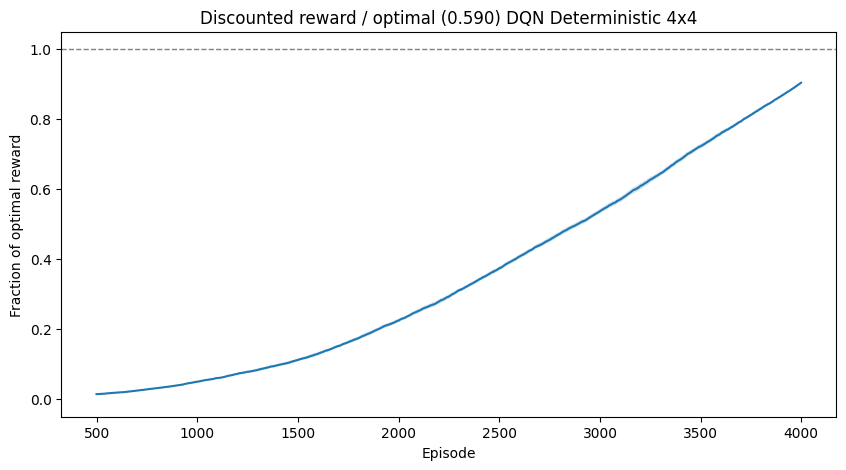

In [9]:
d_rewards4x4_samples = run_samples(deep_q_network_learning, small_lake, slip=0.0, max_steps=16, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Deterministic 4x4", d_rewards4x4_samples, best_reward=d_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed: 10.7min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed: 15.1min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed: 15.9min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed: 16.1min remaining:  8.4min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed: 16.8min remaining:  4.7min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed: 17.3min remaining:  1.8min
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed: 17.7min finished


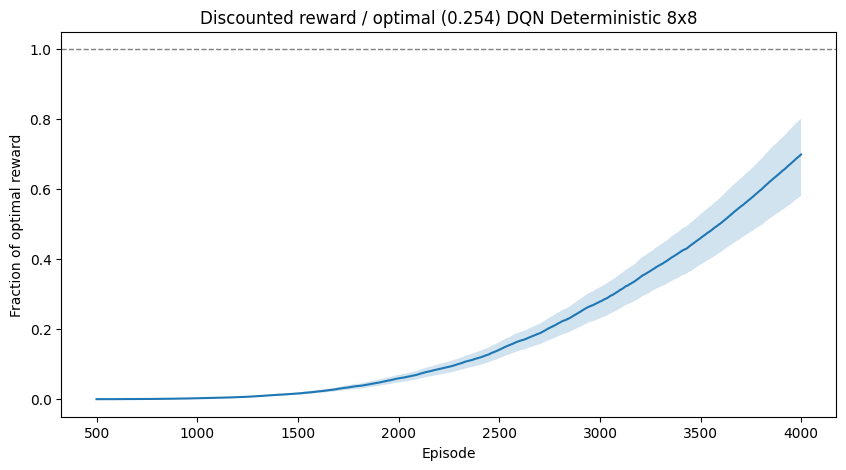

In [11]:
d_rewards8x8_samples = run_samples(deep_q_network_learning, big_lake, slip=0.0, max_steps=64, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Deterministic 8x8", d_rewards8x8_samples, best_reward=d_optimal_vals8x8[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   16.0s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   30.1s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   31.9s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:   46.1s remaining:   24.2s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  1.0min remaining:   16.8s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  1.0min remaining:    6.3s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  1.0min finished


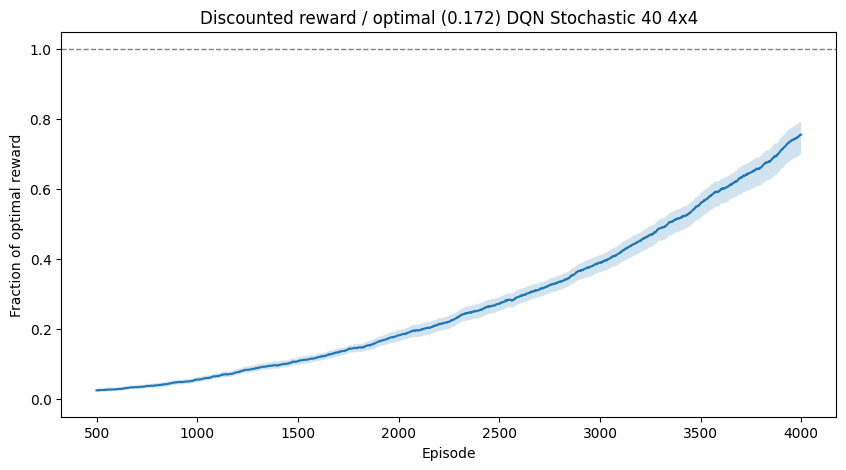

In [12]:
s_40_rewards4x4_samples = run_samples(deep_q_network_learning, small_lake, slip=0.4, max_steps=16, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Stochastic 40 4x4", s_40_rewards4x4_samples, best_reward=s_40_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  1.2min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  2.5min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:  3.0min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  4.1min remaining:  2.1min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  5.2min remaining:  1.4min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  5.3min remaining:   33.1s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  5.5min finished


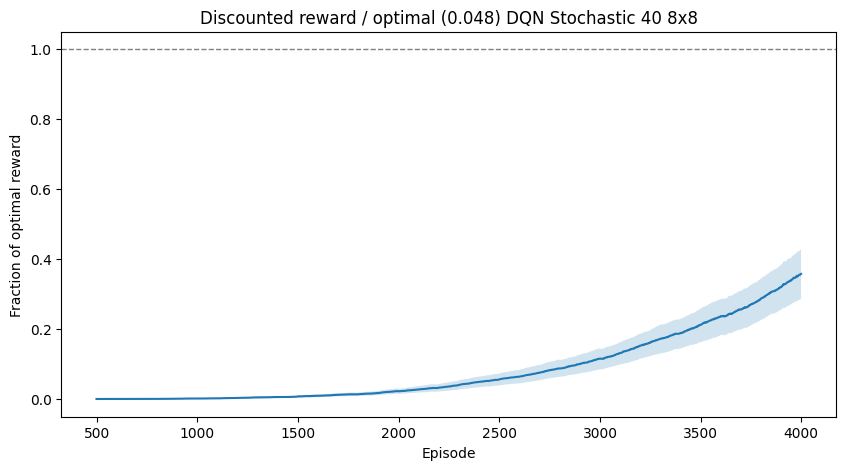

In [13]:
s_40_rewards8x8_samples = run_samples(deep_q_network_learning, big_lake, slip=0.4, max_steps=64, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Stochastic 40 8x8", s_40_rewards8x8_samples, best_reward=s_40_optimal_vals8x8[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   19.8s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   39.5s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   41.0s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  1.0min remaining:   32.0s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  1.3min remaining:   21.0s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  1.3min remaining:    8.3s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  1.3min finished


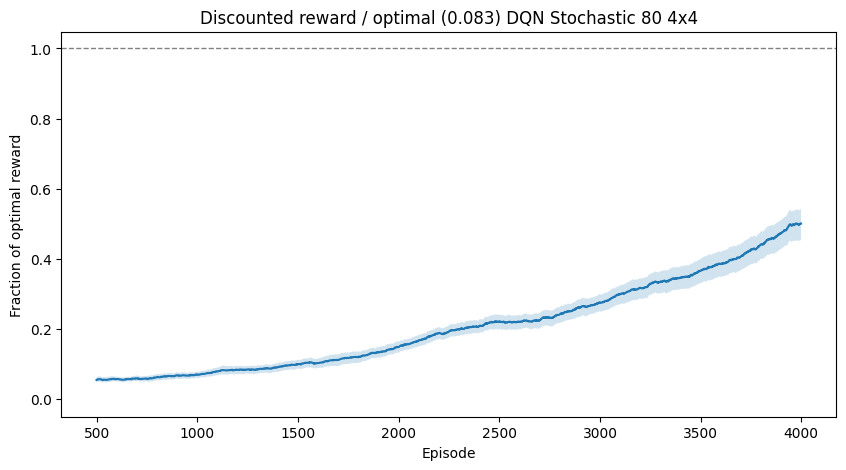

In [14]:
s_80_rewards4x4_samples = run_samples(deep_q_network_learning, small_lake, slip=0.8, max_steps=16, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Stochastic 80 4x4", s_80_rewards4x4_samples, best_reward=s_80_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  1.4min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  2.9min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:  3.2min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  4.4min remaining:  2.3min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  5.7min remaining:  1.6min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  5.8min remaining:   36.2s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  5.9min finished


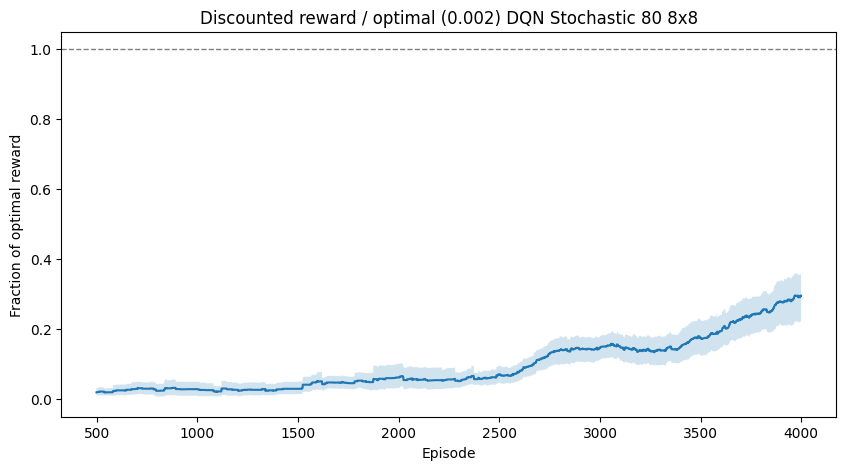

In [57]:
s_80_rewards8x8_samples = run_samples(deep_q_network_learning, big_lake, slip=0.8, max_steps=64, **dqn_kwargs)

plot_results(max_episodes, "DQN", "Stochastic 80 8x8", s_80_rewards8x8_samples, best_reward=s_80_optimal_vals8x8[0])

In [15]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

class BaseBstrapDQN(nn.Module):

    def __init__(self, env, huber_loss, n_heads, n_actions, gamma, learning_rate,
                 kernel_size, conv_out_channels, fc_out_features, seed):
        super().__init__()
        torch.manual_seed(seed)
        self.n_actions = n_actions
        self.huber_loss = huber_loss
        self.n_heads = n_heads
        self.gamma = gamma

        self.conv_layer = nn.Conv2d(in_channels=env.state_shape[0], out_channels=conv_out_channels,
                                    kernel_size=kernel_size, stride=1)

        h = env.h - kernel_size + 1
        w = env.w - kernel_size + 1

        # All heads are evaluated in one batched matmul per layer instead of a Python
        # loop over separate nn.Linear modules. The weights are initialised by building
        # the per-head nn.Linear layers in the same order as before and stacking them,
        # so a given seed gives exactly the same starting network.
        fc_in = h * w * conv_out_channels
        heads = [(nn.Linear(fc_in, fc_out_features), nn.Linear(fc_out_features, n_actions))
                 for _ in range(n_heads)]
        self.head_w1 = nn.Parameter(torch.stack([l1.weight.T for l1, _ in heads]).detach().contiguous())  # [H, F, fc]
        self.head_b1 = nn.Parameter(torch.stack([l1.bias for l1, _ in heads]).detach().unsqueeze(1))     # [H, 1, fc]
        self.head_w2 = nn.Parameter(torch.stack([l2.weight.T for _, l2 in heads]).detach().contiguous())  # [H, fc, A]
        self.head_b2 = nn.Parameter(torch.stack([l2.bias for _, l2 in heads]).detach().unsqueeze(1))     # [H, 1, A]

        self.optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate, foreach=True)

    def forward(self, x):
        x = torch.as_tensor(x, dtype=torch.float32, device=device)
        x = torch.relu(self.conv_layer(x)).flatten(1)
        x = x.unsqueeze(0).expand(self.n_heads, -1, -1)                        # [H, B, F]
        x = torch.relu(torch.baddbmm(self.head_b1, x, self.head_w1))            # [H, B, fc]
        return torch.baddbmm(self.head_b2, x, self.head_w2).transpose(0, 1)     # [B, H, A]

    def compute_q_from_heads(self, q, actions):
        # q: [B, H, A]; actions: [B] (same action for every head) or [B, H] (one per head)
        if actions.dim() == 1:
            actions = actions.unsqueeze(1).expand(-1, self.n_heads)
        return q.gather(2, actions.unsqueeze(-1)).squeeze(-1)  # [B, H]

    def select_action(self, q):
        return self.select_action_vote(q)

    def select_action_vote(self, q):
        votes = q.argmax(dim=-1)                                # [B, H]
        counts = F.one_hot(votes, self.n_actions).sum(dim=1)    # [B, A]
        return counts.argmax(dim=-1)

    def select_action_greedy(self, q):
        return q.mean(dim=1).argmax(dim=-1)

    def train_step(self, transitions, gamma, tdqn):
        # Batched arrays from ReplayBuffer.draw, already float32 / int64, so
        # torch.from_numpy wraps them without copying or converting.
        states, actions, rewards, next_states, terminateds, truncateds = transitions

        actions = torch.from_numpy(actions).to(device)
        rewards = torch.from_numpy(rewards).to(device).unsqueeze(-1)
        not_done = torch.from_numpy((1 - terminateds) * (1 - truncateds)).to(device).unsqueeze(-1)

        q_values = self.compute_q_from_heads(self(states), actions)  # [B, H]

        with torch.no_grad():
            # Double DQN, per head: each online head picks its own greedy action
            # and the matching target head evaluates it.
            next_actions = self(next_states).argmax(dim=-1)                       # [B, H]
            next_q = tdqn.compute_q_from_heads(tdqn(next_states), next_actions)   # [B, H]
            target = rewards + gamma * next_q * not_done

        loss_fn = F.smooth_l1_loss if self.huber_loss else F.mse_loss
        loss = loss_fn(q_values, target)  # mean over batch and heads

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()


class IDSDQN(BaseBstrapDQN):

    def __init__(self, env, huber_loss, n_heads, n_actions, gamma, learning_rate,
                 kernel_size, conv_out_channels, fc_out_features, seed, rho, n_stds):
        super().__init__(env, huber_loss, n_heads, n_actions, gamma, learning_rate,
                         kernel_size, conv_out_channels, fc_out_features, seed)
        self.rho = rho
        self.n_stds = n_stds

    def select_action(self, q):
        return self.select_action_ids(q)

    def select_action_ids(self, q):
        mean = q.mean(dim=1)                    # [B, A]
        var = q.var(dim=1, correction=0)        # [B, A], spread across heads
        std = var.sqrt()
        regret = (mean + self.n_stds * std).max(dim=-1, keepdim=True)[0] - (mean - self.n_stds * std)
        info_gain = torch.log1p(var / self.rho) + 1e-5
        return (regret.square() / info_gain).argmin(dim=-1)


def ids_deep_q_network_learning(env, n_stds, rho, max_episodes, learning_rate, gamma,
                                batch_size, target_update_frequency, buffer_size,
                                kernel_size, conv_out_channels, fc_out_features, seed,
                                learning_starts=0):
    # learning_starts: number of initial agent steps that take uniformly random actions,
    # with no training until then (Nikolov et al., 2019, use 50,000 on Atari). Without it,
    # actions the agent never tries keep their random initial values, and IDS can get stuck
    # repeating one move (e.g. walking into a wall) for the whole run.
    random_state = np.random.RandomState(seed)
    replay_buffer = ReplayBuffer(buffer_size, random_state)
    warmup_rng = np.random.RandomState(10_000 + seed)  # separate RNG: replay sampling is unchanged
    total_steps = 0

    n_actions = env.n_actions
    n_heads = 10  # number of bootstrap heads

    dqn = IDSDQN(env, True, n_heads, n_actions, gamma, learning_rate, kernel_size,
                 conv_out_channels, fc_out_features, seed, rho=rho, n_stds=n_stds).to(device)
    tdqn = IDSDQN(env, True, n_heads, n_actions, gamma, learning_rate, kernel_size,
                  conv_out_channels, fc_out_features, seed, rho=rho, n_stds=n_stds).to(device)
    tdqn.requires_grad_(False)

    sums_of_rewards = []

    for i in range(max_episodes):
        state, encoded_state = env.reset()
        sum_of_discounted_rewards = 0.0
        terminated = False
        truncated = False
        t = 0

        while not (terminated or truncated):
            if total_steps < learning_starts:
                action = warmup_rng.randint(n_actions)
            else:
                with torch.inference_mode():
                    q = dqn(np.asarray(encoded_state)[None])   # [1, H, A]
                    action = dqn.select_action(q).item()

            next_state, encoded_next_state, reward, terminated, truncated, info = env.step(action)

            sum_of_discounted_rewards += gamma ** t * reward
            replay_buffer.append((encoded_state, action, reward, encoded_next_state, terminated, truncated))
            state = next_state
            encoded_state = encoded_next_state
            t += 1
            total_steps += 1

            if len(replay_buffer) >= batch_size and total_steps >= learning_starts:
                transitions = replay_buffer.draw(batch_size)
                dqn.train_step(transitions, gamma, tdqn)

        sums_of_rewards.append(sum_of_discounted_rewards)

        if (i % target_update_frequency) == 0:
            tdqn.load_state_dict(dqn.state_dict())

    return torch.tensor(sums_of_rewards)


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   13.2s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   26.1s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   27.3s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:   39.1s remaining:   20.5s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:   51.1s remaining:   14.3s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:   51.9s remaining:    5.4s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:   52.4s finished


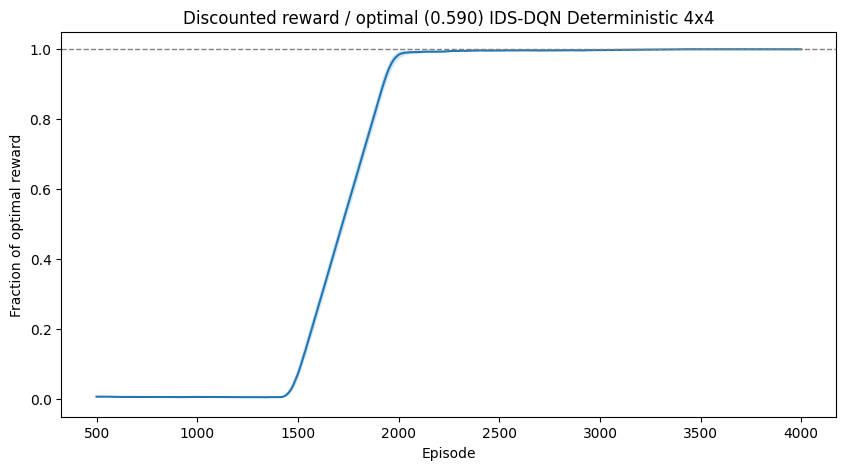

In [16]:
d_rewards4x4_samples = run_samples(ids_deep_q_network_learning, small_lake, slip=0.0, max_steps=16, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Deterministic 4x4", d_rewards4x4_samples, best_reward=d_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   54.2s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  1.9min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:  2.1min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  2.9min remaining:  1.5min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  3.8min remaining:  1.1min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  3.9min remaining:   24.5s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  4.1min finished


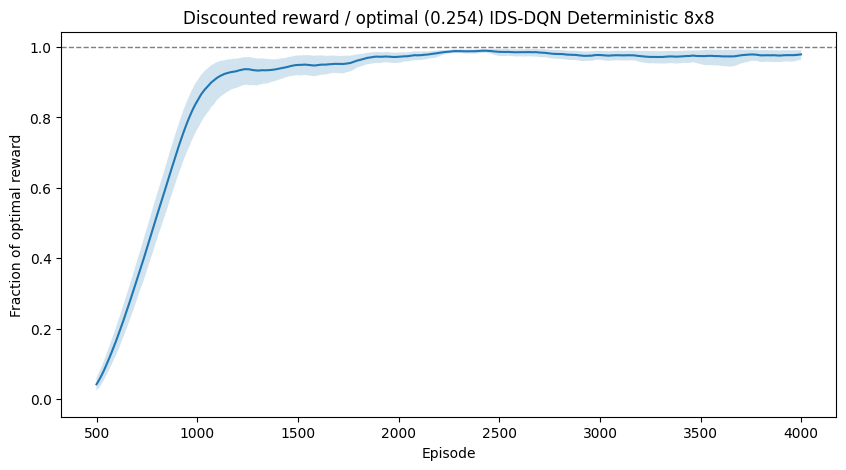

In [17]:
d_rewards8x8_samples = run_samples(ids_deep_q_network_learning, big_lake, slip=0.0, max_steps=64, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Deterministic 8x8", d_rewards8x8_samples, best_reward=d_optimal_vals8x8[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   14.6s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   29.6s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   31.7s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:   45.2s remaining:   23.7s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:   59.8s remaining:   16.7s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  1.0min remaining:    6.2s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  1.0min finished


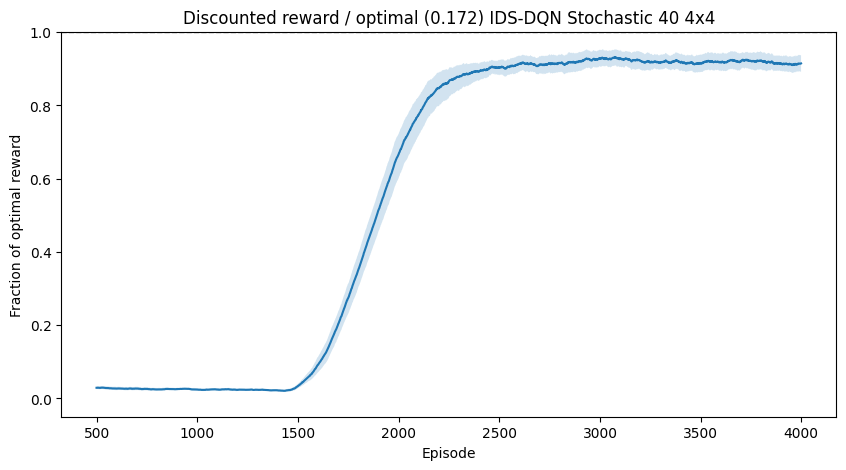

In [18]:
s_40_rewards4x4_samples = run_samples(ids_deep_q_network_learning, small_lake, slip=0.4, max_steps=16, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Stochastic 40 4x4", s_40_rewards4x4_samples, best_reward=s_40_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  1.2min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  2.5min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:  2.8min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  4.2min remaining:  2.2min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  5.4min remaining:  1.5min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  5.6min remaining:   35.0s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  5.9min finished


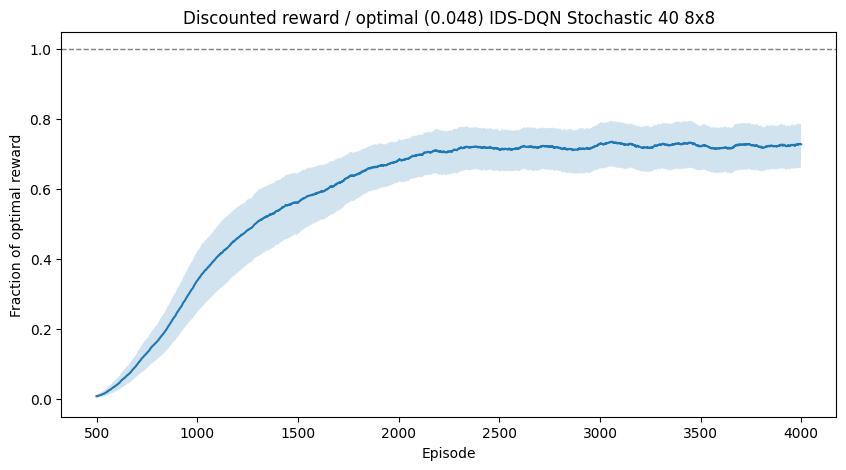

In [19]:
s_40_rewards8x8_samples = run_samples(ids_deep_q_network_learning, big_lake, slip=0.4, max_steps=64, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Stochastic 40 8x8", s_40_rewards8x8_samples, best_reward=s_40_optimal_vals8x8[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   23.0s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:   47.7s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:   49.7s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  1.2min remaining:   38.4s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  1.6min remaining:   27.4s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  1.7min remaining:   10.3s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  1.7min finished


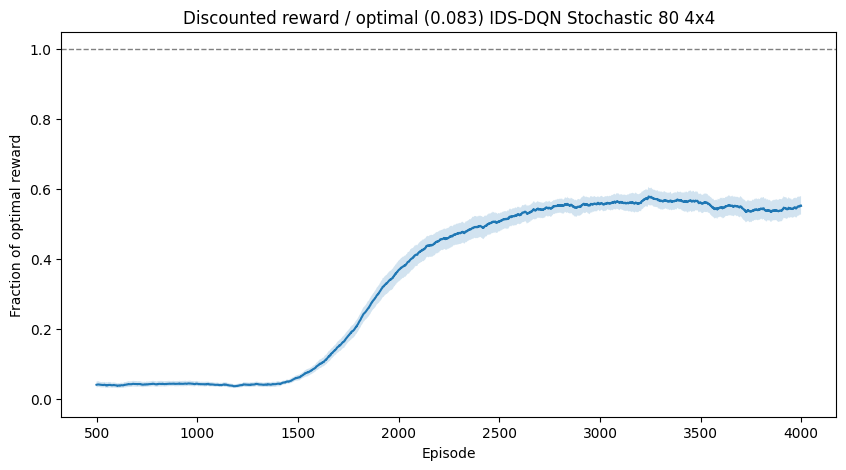

In [20]:
s_80_rewards4x4_samples = run_samples(ids_deep_q_network_learning, small_lake, slip=0.8, max_steps=16, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Stochastic 80 4x4", s_80_rewards4x4_samples, best_reward=s_80_optimal_vals4x4[0])

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  1.8min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  3.9min
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:  4.7min
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:  6.4min remaining:  3.3min
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:  8.2min remaining:  2.3min
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:  8.5min remaining:   52.6s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:  8.8min finished


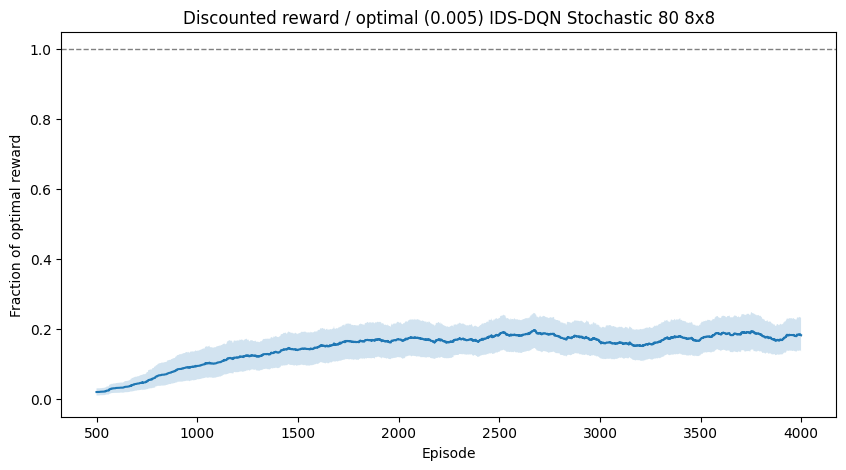

In [21]:
s_80_rewards8x8_samples = run_samples(ids_deep_q_network_learning, big_lake, slip=0.8, max_steps=64, **ids_kwargs)

plot_results(max_episodes, "IDS-DQN", "Stochastic 80 8x8", s_80_rewards8x8_samples, best_reward=s_80_optimal_vals8x8[0])